# Task 1 — RankUp + TabM: Optuna Gaussian Noise

Self-contained Kaggle notebook untuk mencari kekuatan weak/strong augmentation terbaik pada
lima dataset ordinal. Objective adalah validation MAE; test hanya dipakai setelah konfigurasi
terbaik dipilih. Set `SMOKE_TEST = True` untuk pemeriksaan ESL 2 trial × 3 epoch.

# 1. Setup

Dependency minimum dan lokasi output Kaggle.

In [1]:
%pip install -q optuna tabm

import gc
import random
import time
from importlib.metadata import version
from itertools import islice
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from scipy.stats import spearmanr
from sklearn.metrics import cohen_kappa_score, mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tabm import TabM
from torch.utils.data import DataLoader, TensorDataset

optuna.logging.set_verbosity(optuna.logging.WARNING)

ROOT = Path("/kaggle/working/task1_weak_strong_optuna")
RESULTS = ROOT / "results"
RESULTS.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GPU_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
print(f"device={DEVICE} | GPU={GPU_NAME}")
print(f"PyTorch={torch.__version__} | Optuna={optuna.__version__} | TabM={version('tabm')}")

Note: you may need to restart the kernel to use updated packages.
device=cuda | GPU=Tesla T4
PyTorch=2.10.0+cu128 | Optuna=4.9.0 | TabM=0.0.3


# 2. Configuration

Pada tahap Optuna, 20% dari **outer train** menjadi validation. Sisa 80% adalah SSL training
pool; 10% dari pool tersebut labeled dan 90% unlabeled. Semua split dibuat sekali dengan seed 42
dan dipakai ulang oleh seluruh trial. Setelah tuning, validation digabung kembali ke outer train;
final training membuat split baru 10% labeled / 90% unlabeled dari seluruh outer train.

In [2]:
AUGMENTATION = "gaussian"
WEAK_AXIS = "weak_sigma"
STRONG_AXIS = "strong_sigma"


SEED = 42
LABELED_FRACTION = 0.10
VALIDATION_FRACTION = 0.20
OPTUNA_EPOCHS = 40
FINAL_EPOCHS = 120
N_TRIALS = 200
VAL_EVERY = 5
SMOKE_TEST = False

BATCH_SIZE = 32
MAX_RANKUP_STEPS = 100
W_RANK = 0.2
W_UNLABELED = 0.2
P_CUTOFF = 0.95
LEARNING_RATE = 2e-3
WEIGHT_DECAY = 3e-4
DONOR_MIN_CONFIDENCE = 0.8
RLA_NUM_BINS = 4

DATASETS = {
    "melbourneAirbnb": {
        "filename": "oc10_melbourneAirbnb.csv",
        "train": 16028,
        "test": 4008,
        "features": 48,
        "classes": 10,
    },
    "studentPerformance": {
        "filename": "oc08_studentPerformance.csv",
        "train": 529,
        "test": 133,
        "features": 43,
        "classes": 8,
    },
    "nhanes": {
        "filename": "oc05_nhanes.csv",
        "train": 4178,
        "test": 1045,
        "features": 30,
        "classes": 5,
    },
    "esl": {
        "filename": "oc06_esl.csv",
        "train": 390,
        "test": 98,
        "features": 4,
        "classes": 6,
    },
    "lev": {
        "filename": "oc05_lev.csv",
        "train": 800,
        "test": 200,
        "features": 4,
        "classes": 5,
    },
}

RUN_DATASETS = ["esl"] if SMOKE_TEST else list(DATASETS)
RUN_OPTUNA_EPOCHS = 3 if SMOKE_TEST else OPTUNA_EPOCHS
RUN_FINAL_EPOCHS = 3 if SMOKE_TEST else FINAL_EPOCHS

# 3. Load Dataset

Kelima CSV dicari secara rekursif hanya dari `/kaggle/input`.

In [3]:
def find_dataset(filename):
    path = next(Path("/kaggle/input").rglob(filename), None)
    if path is None:
        raise FileNotFoundError(filename)
    return path


def load_dataset(name):
    spec = DATASETS[name]
    frame = pd.read_csv(find_dataset(spec["filename"]))
    if "y" not in frame.columns or frame.isna().any().any():
        raise ValueError(f"{name}: target y wajib ada dan data tidak boleh missing")
    if len(frame.select_dtypes(include=np.number).columns) != len(frame.columns):
        raise ValueError(f"{name}: semua kolom harus numerik")
    classes = np.sort(frame["y"].unique())
    if not np.array_equal(classes, np.arange(spec["classes"])):
        raise ValueError(f"{name}: kelas harus 0..{spec['classes'] - 1}")
    if frame.shape != (spec["train"] + spec["test"], spec["features"] + 1):
        raise ValueError(f"{name}: shape {frame.shape} tidak sesuai spesifikasi")
    return frame


frames = {name: load_dataset(name) for name in RUN_DATASETS}

# 4. Fixed Split

Outer train/test 70/30, validation 20% dari outer train, lalu SSL train dibagi 10% labeled dan 90% unlabeled. Split dibuat sekali dengan seed 42.

In [4]:
def fixed_split(frame, name):
    y = frame["y"].to_numpy(dtype=np.int64)
    outer_train, test = train_test_split(
        np.arange(len(frame)), test_size=0.20, random_state=SEED, stratify=y
    )
    spec = DATASETS[name]
    assert (len(outer_train), len(test)) == (spec["train"], spec["test"])
    ssl_train, validation = train_test_split(
        outer_train, test_size=VALIDATION_FRACTION, random_state=SEED,
        stratify=y[outer_train],
    )
    n_labeled = max(spec["classes"], round(LABELED_FRACTION * len(ssl_train)))
    labeled, unlabeled = train_test_split(
        ssl_train, train_size=n_labeled, random_state=SEED, stratify=y[ssl_train]
    )
    return {
        "outer_train": outer_train, "test": test,
        "ssl_train": ssl_train, "validation": validation,
        "labeled": labeled, "unlabeled": unlabeled,
    }


splits = {name: fixed_split(frame, name) for name, frame in frames.items()}

# 5. Preprocessing

Pada Optuna, input scaler di-fit hanya pada SSL training pool dan target scaler hanya pada labeled
target di pool tersebut. Pada final training, input scaler di-fit ulang pada seluruh outer train dan
target scaler di-fit ulang pada labeled target final. Validation/test tidak pernah dipakai untuk fit.

In [5]:
def tensorize(frame, train_pool, labeled, unlabeled, evaluation, evaluation_name):
    X = frame.drop(columns="y").to_numpy(dtype=np.float32)
    y = frame["y"].to_numpy(dtype=np.int64)
    x_scaler = StandardScaler().fit(X[train_pool])
    y_scaler = StandardScaler().fit(y[labeled, None].astype(np.float32))
    X = x_scaler.transform(X).astype(np.float32)
    y_scaled = y_scaler.transform(y[:, None].astype(np.float32)).astype(np.float32)
    tensor = torch.from_numpy
    return {
        "x_labeled": tensor(X[labeled]),
        "y_labeled": tensor(y_scaled[labeled]),
        "x_unlabeled": tensor(X[unlabeled]),
        "y_unlabeled_hidden": tensor(y[unlabeled]),
        f"x_{evaluation_name}": tensor(X[evaluation]),
        f"y_{evaluation_name}": y[evaluation],
        f"{evaluation_name}_indices": evaluation,
        "x_train_pool": tensor(X[train_pool]),
        "y_scale": float(y_scaler.scale_[0]),
        "y_mean": float(y_scaler.mean_[0]),
        "n_features": X.shape[1],
        "class_min": int(y[train_pool].min()),
        "class_max": int(y[train_pool].max()),
    }


def prepare_optuna_data(frame, split):
    return tensorize(
        frame, split["ssl_train"], split["labeled"], split["unlabeled"],
        split["validation"], "validation",
    )


def prepare_final_data(frame, split):
    y = frame["y"].to_numpy(dtype=np.int64)
    n_classes = len(np.unique(y[split["outer_train"]]))
    n_labeled = max(n_classes, round(LABELED_FRACTION * len(split["outer_train"])))
    labeled, unlabeled = train_test_split(
        split["outer_train"], train_size=n_labeled, random_state=SEED,
        stratify=y[split["outer_train"]],
    )
    return tensorize(
        frame, split["outer_train"], labeled, unlabeled, split["test"], "test"
    )




# 6. TabM

Arsitektur lama dipertahankan: satu regression output dan dua ranking logits (`d_out=3`).

In [6]:
class TabMRankUp(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.model = TabM.make(n_num_features=n_features, d_out=3)

    def forward(self, x):
        output = self.model(x)
        return output[..., :1], output[..., 1:]

# 7. RankUp

Loss tetap terdiri dari L1 regression, supervised pairwise ranking, dan confidence-filtered unlabeled pseudo-ranking.

In [7]:
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def make_loader(*tensors, shuffle=True):
    return DataLoader(
        TensorDataset(*tensors), batch_size=BATCH_SIZE, shuffle=shuffle,
        generator=torch.Generator().manual_seed(SEED),
        pin_memory=torch.cuda.is_available(),
    )


def regression_loss(prediction, target):
    return F.l1_loss(prediction, target[:, None, :].expand_as(prediction))


def pairwise_logits(rank_logits):
    rank_logits = rank_logits.permute(1, 0, 2)
    return rank_logits[:, :, None, :] - rank_logits[:, None, :, :]


def pairwise_targets(target):
    difference = target[:, None, 0] - target[None, :, 0]
    probability = difference.gt(0).float() + 0.5 * difference.eq(0).float()
    return torch.stack([1 - probability, probability], dim=-1)


def supervised_rank_loss(rank_logits, target):
    logits = pairwise_logits(rank_logits)
    targets = pairwise_targets(target).unsqueeze(0).expand(logits.shape[0], -1, -1, -1)
    return F.cross_entropy(logits.reshape(-1, 2), targets.reshape(-1, 2))


def pseudo_rank_loss(weak_logits, strong_logits):
    weak_probability = F.softmax(pairwise_logits(weak_logits), dim=-1).mean(0)
    confidence, pseudo_target = weak_probability.max(dim=-1)
    strong_pairs = pairwise_logits(strong_logits)
    valid = ~torch.eye(len(confidence), dtype=torch.bool, device=confidence.device)
    accepted = confidence.ge(P_CUTOFF) & valid
    targets = pseudo_target.unsqueeze(0).expand(strong_pairs.shape[0], -1, -1)
    losses = F.cross_entropy(
        strong_pairs.reshape(-1, 2), targets.reshape(-1), reduction="none"
    ).reshape_as(targets)
    mask = accepted.unsqueeze(0).expand_as(targets)
    loss = losses[mask].mean() if mask.any() else losses.sum() * 0
    return loss, {
        "pseudo_target": pseudo_target.detach(),
        "confidence": confidence.detach(),
        "accepted": accepted.detach(),
        "valid": valid.detach(),
    }


def predict_scores(model, x, data):
    outputs = []
    model.eval()
    loader = DataLoader(
        TensorDataset(x), batch_size=1024, shuffle=False,
        pin_memory=torch.cuda.is_available(),
    )
    with torch.inference_mode():
        for (xb,) in loader:
            prediction, _ = model(xb.to(DEVICE, non_blocking=True))
            outputs.append(prediction.mean(dim=1).cpu().numpy())
    scaled = np.concatenate(outputs).reshape(-1)
    return scaled * data["y_scale"] + data["y_mean"]


def evaluate_metrics(y_true, score, data):
    predicted = np.clip(np.rint(score), data["class_min"], data["class_max"]).astype(int)
    correlation = spearmanr(y_true, score).statistic
    return {
        "R2": r2_score(y_true, score),
        "Spearman": 0.0 if np.isnan(correlation) else correlation,
        "MAE": mean_absolute_error(y_true, score),
        "RMSE": mean_squared_error(y_true, score) ** 0.5,
        "QWK": cohen_kappa_score(y_true, predicted, weights="quadratic"),
    }

# 8. Augmentation


        **Original method.** [Alsaggaf et al. (2024)](https://doi.org/10.1093/bfgp/elad059)
        add Gaussian noise to scRNA-seq profiles to form contrastive views for cell-type identification.

        **RankUp adaptation.** Here every standardized tabular feature receives independent zero-mean
        Gaussian noise. Optuna searches fixed `weak_sigma` and `relative_gap` ranges; strong sigma is derived deterministically.
        These ranges and the weak/strong interpretation are experimental RankUp choices, not parameters
        claimed by the original paper.

In [8]:
def strong_sigma_from_gap(weak_sigma, relative_gap):
    return weak_sigma + (1.50 - weak_sigma) * relative_gap


def suggest_parameters(trial, data):
    weak_sigma = trial.suggest_float("weak_sigma", 0.005, 1.40, log=True)
    relative_gap = trial.suggest_float("relative_gap", 0.001, 1.0)
    return {
        "weak_sigma": weak_sigma,
        "relative_gap": relative_gap,
        "strong_sigma": strong_sigma_from_gap(weak_sigma, relative_gap),
    }


def parameter_metadata(params, data):
    return {
        "weak_parameter": params["weak_sigma"],
        "strong_parameter": params["strong_sigma"],
        "weak_sigma": params["weak_sigma"],
        "relative_gap": params["relative_gap"],
        "strong_sigma": params["strong_sigma"],
    }

In [9]:
def augment_views(x, data, params, scores):
    weak_noise = torch.randn_like(x) * params["weak_sigma"]
    strong_noise = torch.randn_like(x) * params["strong_sigma"]
    return x + weak_noise, x + strong_noise, {
        "weak_noise_abs_mean": weak_noise.abs().mean().item(),
        "strong_noise_abs_mean": strong_noise.abs().mean().item(),
        "weak_noise_std_actual": weak_noise.std(unbiased=False).item(),
        "strong_noise_std_actual": strong_noise.std(unbiased=False).item(),
    }, {}

In [10]:
x_demo = torch.zeros(20000, 4, device=DEVICE)
for weak_sigma, relative_gap in [(0.005, 0.001), (0.70, 0.50), (1.40, 1.0)]:
    actual_strong = strong_sigma_from_gap(weak_sigma, relative_gap)
    assert 0 < weak_sigma < actual_strong <= 1.50
weak, strong, stats, _ = augment_views(
    x_demo, {}, {"weak_sigma": 1.20, "strong_sigma": 1.50}, None
)
assert 1.20 < 1.50
assert not torch.equal(weak, strong)
assert abs(stats["weak_noise_std_actual"] - 1.20) < 0.03
assert abs(stats["strong_noise_std_actual"] - 1.50) < 0.03
print("Gaussian sanity check: OK")

Gaussian sanity check: OK


In [11]:
optuna_data = {
    name: prepare_optuna_data(frames[name], splits[name])
    for name in RUN_DATASETS
}
display(pd.DataFrame([
    {
        "dataset": name,
        "outer_train": len(splits[name]["outer_train"]),
        "ssl_train": len(splits[name]["ssl_train"]),
        "labeled": len(data["x_labeled"]),
        "unlabeled": len(data["x_unlabeled"]),
        "validation": len(data["x_validation"]),
        "test": len(splits[name]["test"]),
    }
    for name, data in optuna_data.items()
]))

,dataset,outer_train,ssl_train,labeled,unlabeled,validation,test
0,melbourneAirbnb,16028,12822,1282,11540,3206,4008
1,studentPerformance,529,423,42,381,106,133
2,nhanes,4178,3342,334,3008,836,1045
3,esl,390,312,31,281,78,98
4,lev,800,640,64,576,160,200


# 9. Pseudo-ranking Diagnostics

Hidden unlabeled ground truth hanya dipakai setelah pseudo-pair dan augmentasi terbentuk. Label ini
tidak masuk loss, model input, pseudo-class generation, threshold, atau donor selection. Epoch metric
dihitung dari jumlah pair/sample total, bukan rata-rata accuracy per batch. True ties dikeluarkan dari
`pseudo_rank_accuracy_non_tie`. Pseudo-class hanya diagnostic dan helper donor TabCutMix.

In [12]:
def diagnose_pseudo_ranking(info, y_hidden):
    pseudo = info["pseudo_target"]
    confidence = info["confidence"]
    accepted = info["accepted"]
    valid = info["valid"]
    difference = y_hidden[:, None] - y_hidden[None, :]
    accepted_non_tie = accepted & difference.ne(0)
    correct = pseudo.eq(difference.gt(0).long()) & accepted_non_tie
    return {
        "pseudo_pair_total": int(valid.sum().item()),
        "pseudo_pair_accepted": int(accepted.sum().item()),
        "pseudo_non_tie_total": int(accepted_non_tie.sum().item()),
        "pseudo_non_tie_correct": int(correct.sum().item()),
        "pseudo_confidence_sum": float(confidence[valid].sum().item()),
    }


def diagnose_pseudo_class(scores, y_hidden, data):
    raw = scores.flatten() * data["y_scale"] + data["y_mean"]
    pseudo = raw.round().clamp(data["class_min"], data["class_max"]).long()
    return {
        "pseudo_class_total": len(pseudo),
        "pseudo_class_correct": int(pseudo.eq(y_hidden).sum().item()),
        "pseudo_class_absolute_error": float((pseudo.float() - y_hidden.float()).abs().sum().item()),
    }

# 10. Training

Validation dihitung setiap lima epoch. History hanya menyimpan scalar CPU.

In [13]:
COUNT_COLUMNS = [
    "pseudo_pair_total", "pseudo_pair_accepted", "pseudo_non_tie_total",
    "pseudo_non_tie_correct", "pseudo_class_total", "pseudo_class_correct",
    "pseudo_class_absolute_error", "pseudo_confidence_sum",
]


def aggregate_epoch(batches):
    row = {
        key: float(np.mean([batch[key] for batch in batches]))
        for key in ["total_loss", "regression_loss", "rank_labeled_loss", "rank_unlabeled_loss"]
    }
    for key in COUNT_COLUMNS:
        row[key] = sum(batch.get(key, 0) for batch in batches)
    pair_total = max(1, row["pseudo_pair_total"])
    class_total = max(1, row["pseudo_class_total"])
    row.update({
        "pseudo_accept_rate": row["pseudo_pair_accepted"] / pair_total,
        "pseudo_rank_accuracy_non_tie": (
            row["pseudo_non_tie_correct"] / row["pseudo_non_tie_total"]
            if row["pseudo_non_tie_total"] else np.nan
        ),
        "pseudo_rank_accuracy": (
            row["pseudo_non_tie_correct"] / row["pseudo_non_tie_total"]
            if row["pseudo_non_tie_total"] else np.nan
        ),
        "pseudo_class_accuracy": row["pseudo_class_correct"] / class_total,
        "pseudo_class_mae": row["pseudo_class_absolute_error"] / class_total,
        "pseudo_confidence_mean": row["pseudo_confidence_sum"] / pair_total,
    })
    for key in set().union(*(batch.keys() for batch in batches)) - set(row):
        values = [batch[key] for batch in batches if key in batch and np.isfinite(batch[key])]
        if values:
            row[key] = float(np.mean(values))
    return row


def train_rankup(data, params, epochs, dataset_name, trial=None, history_rows=None):
    set_seed()
    model = TabMRankUp(data["n_features"]).to(DEVICE)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    labeled_loader = make_loader(data["x_labeled"], data["y_labeled"])
    unlabeled_loader = make_loader(data["x_unlabeled"], data["y_unlabeled_hidden"])
    best_metrics, best_epoch, local_history = None, None, []

    for epoch in range(1, epochs + 1):
        model.train()
        batches = []
        labeled_iterator = iter(labeled_loader)
        for x_u, y_u_hidden in islice(unlabeled_loader, MAX_RANKUP_STEPS):
            try:
                x_l, y_l = next(labeled_iterator)
            except StopIteration:
                labeled_iterator = iter(labeled_loader)
                x_l, y_l = next(labeled_iterator)
            x_l = x_l.to(DEVICE, non_blocking=True)
            y_l = y_l.to(DEVICE, non_blocking=True)
            x_u = x_u.to(DEVICE, non_blocking=True)
            y_u_hidden = y_u_hidden.to(DEVICE, non_blocking=True)

            with torch.no_grad():
                prediction_u, _ = model(x_u)
                scores_u = prediction_u.mean(dim=1)
            weak, strong, augmentation_stats, _ = augment_views(
                x_u, data, params, scores_u
            )

            optimizer.zero_grad(set_to_none=True)
            prediction_l, rank_labeled = model(x_l)
            loss_regression = regression_loss(prediction_l, y_l)
            loss_rank_labeled = supervised_rank_loss(rank_labeled, y_l)
            with torch.no_grad():
                _, rank_weak = model(weak)
            _, rank_strong = model(strong)
            loss_rank_unlabeled, pseudo_info = pseudo_rank_loss(rank_weak, rank_strong)
            total_loss = (
                loss_regression + W_RANK * loss_rank_labeled
                + W_UNLABELED * loss_rank_unlabeled
            )
            total_loss.backward()
            optimizer.step()
            batches.append({
                "total_loss": total_loss.item(),
                "regression_loss": loss_regression.item(),
                "rank_labeled_loss": loss_rank_labeled.item(),
                "rank_unlabeled_loss": loss_rank_unlabeled.item(),
                **diagnose_pseudo_ranking(pseudo_info, y_u_hidden),
                **diagnose_pseudo_class(scores_u, y_u_hidden, data),
                **augmentation_stats,
            })

        epoch_stats = aggregate_epoch(batches)
        val_metrics = None
        if "x_validation" in data and (epoch % VAL_EVERY == 0 or epoch == epochs):
            score = predict_scores(model, data["x_validation"], data)
            val_metrics = evaluate_metrics(data["y_validation"], score, data)
            if best_metrics is None or val_metrics["MAE"] < best_metrics["MAE"]:
                best_metrics, best_epoch = val_metrics, epoch

        row = {
            "dataset": dataset_name,
            "augmentation": AUGMENTATION,
            "trial": trial.number if trial is not None else "final",
            "epoch": epoch,
            **parameter_metadata(params, data),
            **epoch_stats,
            **{f"val_{key}": (val_metrics or {}).get(key, np.nan) for key in ["R2", "Spearman", "MAE", "RMSE", "QWK"]},
        }
        local_history.append(row)
        if history_rows is not None:
            history_rows.append(row)

        if trial is not None:
            trial.set_user_attr("epoch_reached", epoch)
            for key, value in epoch_stats.items():
                if np.isfinite(value):
                    trial.set_user_attr(key, float(value))
            if val_metrics is not None:
                for key, value in best_metrics.items():
                    trial.set_user_attr(f"val_{key}", float(value))
                trial.set_user_attr("best_epoch", int(best_epoch))
                trial.report(val_metrics["MAE"], step=epoch)
                if trial.should_prune():
                    raise optuna.TrialPruned()

    return model, local_history, best_metrics, best_epoch

# 11. Optuna Objective

Objective adalah validation MAE. Study hanya berada di memory; CSV diperbarui setelah setiap trial.

In [14]:
def trial_parameters(frozen, data):
    params = dict(frozen.params)
    if params:
        params["strong_sigma"] = strong_sigma_from_gap(
            params["weak_sigma"], params["relative_gap"]
        )
    return params


def trials_frame(study, dataset_name, data):
    rows = []
    for frozen in study.trials:
        params = trial_parameters(frozen, data)
        attrs = frozen.user_attrs
        rows.append({
            "dataset": dataset_name,
            "augmentation": AUGMENTATION,
            "trial": frozen.number,
            "state": frozen.state.name,
            "seed": SEED,
            **(parameter_metadata(params, data) if params else {}),
            "best_epoch": attrs.get("best_epoch", np.nan),
            "val_R2": attrs.get("val_R2", np.nan),
            "val_Spearman": attrs.get("val_Spearman", np.nan),
            "val_MAE": attrs.get("val_MAE", np.nan),
            "val_RMSE": attrs.get("val_RMSE", np.nan),
            "val_QWK": attrs.get("val_QWK", np.nan),
            "pseudo_rank_accuracy": attrs.get("pseudo_rank_accuracy_non_tie", np.nan),
            "pseudo_accept_rate": attrs.get("pseudo_accept_rate", np.nan),
            "pseudo_class_accuracy": attrs.get("pseudo_class_accuracy", np.nan),
            "epoch_reached": attrs.get("epoch_reached", np.nan),
            "training_seconds": attrs.get("training_seconds", np.nan),
            **{key: value for key, value in attrs.items() if key not in {
                "best_epoch", "val_R2", "val_Spearman", "val_MAE", "val_RMSE",
                "val_QWK", "pseudo_rank_accuracy_non_tie", "pseudo_accept_rate",
                "pseudo_class_accuracy", "epoch_reached", "training_seconds",
            }},
        })
    return pd.DataFrame(rows)


def run_study(dataset_name, data):
    output_name = f"{dataset_name}__smoke" if SMOKE_TEST else dataset_name
    dataset_dir = RESULTS / AUGMENTATION / output_name
    (dataset_dir / "plots").mkdir(parents=True, exist_ok=True)
    history_rows = []

    sampler = optuna.samplers.TPESampler(seed=SEED)
    n_trials = 2 if SMOKE_TEST else N_TRIALS

    study = optuna.create_study(
        direction="minimize",
        sampler=sampler,
        pruner=optuna.pruners.MedianPruner(
            n_startup_trials=10, n_warmup_steps=10, interval_steps=5
        ),
    )

    def objective(trial):
        params = suggest_parameters(trial, data)
        started = time.perf_counter()
        model = None
        try:
            model, _, best_metrics, best_epoch = train_rankup(
                data, params, RUN_OPTUNA_EPOCHS, dataset_name, trial, history_rows
            )
            for key, value in best_metrics.items():
                trial.set_user_attr(f"val_{key}", float(value))
            trial.set_user_attr("best_epoch", int(best_epoch))
            return best_metrics["MAE"]
        finally:
            trial.set_user_attr("training_seconds", time.perf_counter() - started)
            if model is not None:
                del model
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    def save_progress(study, frozen_trial):
        trials_frame(study, dataset_name, data).to_csv(dataset_dir / "trials.csv", index=False)
        pd.DataFrame(history_rows).to_csv(dataset_dir / "epoch_history.csv", index=False)

    study.optimize(
        objective, n_trials=n_trials, n_jobs=1,
        callbacks=[save_progress], gc_after_trial=True,
    )
    save_progress(study, study.best_trial)
    return study, pd.DataFrame(history_rows), dataset_dir

# 12. Run Optuna for 5 Datasets

Continuous search menjalankan 200 proposal valid per dataset memakai fixed search space
`weak_sigma` dan `relative_gap`. Smoke mode menjalankan ESL, 2 trial, 3 epoch.

In [15]:
studies, epoch_tables, dataset_dirs = {}, {}, {}
for dataset_name in RUN_DATASETS:
    study, history, dataset_dir = run_study(dataset_name, optuna_data[dataset_name])
    studies[dataset_name] = study
    epoch_tables[dataset_name] = history
    dataset_dirs[dataset_name] = dataset_dir
    print(f"{dataset_name}: best trial={study.best_trial.number}, val MAE={study.best_value:.4f}")

melbourneAirbnb: best trial=115, val MAE=1.3722
studentPerformance: best trial=64, val MAE=1.3738
nhanes: best trial=107, val MAE=0.7945
esl: best trial=4, val MAE=0.4549
lev: best trial=135, val MAE=0.5412


# 13. Best Parameter

In [16]:
best_parameters = pd.DataFrame([
    {
        "dataset": name,
        "best_trial": study.best_trial.number,
        **parameter_metadata(trial_parameters(study.best_trial, optuna_data[name]), optuna_data[name]),
        "best_val_MAE": study.best_value,
    }
    for name, study in studies.items()
])
display(best_parameters)

,dataset,best_trial,weak_parameter,strong_parameter,weak_sigma,relative_gap,strong_sigma,best_val_MAE
0,melbourneAirbnb,115,0.074954,0.520683,0.074954,0.312782,0.520683,1.372154
1,studentPerformance,64,1.225239,1.245054,1.225239,0.072116,1.245054,1.373779
2,nhanes,107,1.398780,1.411422,1.398780,0.124892,1.411422,0.794468
3,esl,4,0.147909,1.105682,0.147909,0.708365,1.105682,0.454860
4,lev,135,0.765054,0.783882,0.765054,0.025619,0.783882,0.541168


# 14. Final Retraining

Validation digabung kembali ke outer train. Model baru dilatih dari nol selama 120 epoch, lalu test dievaluasi satu kali.

In [17]:
def final_train_and_save(dataset_name, study, dataset_dir):
    data = prepare_final_data(frames[dataset_name], splits[dataset_name])
    params = trial_parameters(study.best_trial, data)
    started = time.perf_counter()
    model, final_history, _, _ = train_rankup(
        data, params, RUN_FINAL_EPOCHS, dataset_name
    )
    training_seconds = time.perf_counter() - started
    pd.DataFrame(final_history).to_csv(dataset_dir / "final_epoch_history.csv", index=False)

    score = predict_scores(model, data["x_test"], data)
    test_metrics = evaluate_metrics(data["y_test"], score, data)
    predicted_class = np.clip(
        np.rint(score), data["class_min"], data["class_max"]
    ).astype(int)
    pd.DataFrame({
        "sample_index": data["test_indices"],
        "y_true": data["y_test"],
        "continuous_prediction": score,
        "predicted_class": predicted_class,
    }).to_csv(dataset_dir / "final_predictions.csv", index=False)

    attrs = study.best_trial.user_attrs
    last = final_history[-1]
    result = {
        "dataset": dataset_name,
        "augmentation": AUGMENTATION,
        "best_trial": study.best_trial.number,
        "best_weak": parameter_metadata(params, data)["weak_parameter"],
        "best_strong": parameter_metadata(params, data)["strong_parameter"],
        **parameter_metadata(params, data),
        **{f"best_val_{key}": attrs.get(f"val_{key}", np.nan) for key in ["R2", "Spearman", "MAE", "RMSE", "QWK"]},
        **{f"test_{key}": value for key, value in test_metrics.items()},
        "final_pseudo_rank_accuracy": last["pseudo_rank_accuracy_non_tie"],
        "final_pseudo_accept_rate": last["pseudo_accept_rate"],
        "final_pseudo_class_accuracy": last["pseudo_class_accuracy"],
        "training_seconds": training_seconds,
        "seed": SEED,
        "hardware": GPU_NAME,
    }
    pd.DataFrame([result]).to_csv(dataset_dir / "best_result.csv", index=False)
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return result, pd.DataFrame(final_history)


final_rows, final_histories = [], {}
for dataset_name in RUN_DATASETS:
    result, final_history = final_train_and_save(
        dataset_name, studies[dataset_name], dataset_dirs[dataset_name]
    )
    final_rows.append(result)
    final_histories[dataset_name] = final_history

all_best_results = pd.DataFrame(final_rows)
all_best_results.to_csv(RESULTS / AUGMENTATION / "all_best_results.csv", index=False)
display(all_best_results)

,dataset,augmentation,best_trial,best_weak,best_strong,weak_parameter,strong_parameter,weak_sigma,relative_gap,strong_sigma,...,test_Spearman,test_MAE,test_RMSE,test_QWK,final_pseudo_rank_accuracy,final_pseudo_accept_rate,final_pseudo_class_accuracy,training_seconds,seed,hardware
0,melbourneAirbnb,gaussian,115,0.074954,0.520683,0.074954,0.520683,0.074954,0.312782,0.520683,...,0.809086,1.288659,1.750281,0.802598,0.951062,0.525645,0.283750,112.043827,42,Tesla T4
1,studentPerformance,gaussian,64,1.225239,1.245054,1.225239,1.245054,1.225239,0.072116,1.245054,...,0.395773,1.307495,1.688458,0.270594,0.651288,0.391150,0.258403,16.889159,42,Tesla T4
2,nhanes,gaussian,107,1.398780,1.411422,1.398780,1.411422,1.398780,0.124892,1.411422,...,0.244660,0.787253,0.997298,0.155340,0.748842,0.314113,0.414062,111.671988,42,Tesla T4
3,esl,gaussian,4,0.147909,1.105682,0.147909,1.105682,0.147909,0.708365,1.105682,...,0.926788,0.416936,0.562577,0.874819,0.995804,0.552811,0.643875,12.255181,42,Tesla T4
4,lev,gaussian,135,0.765054,0.783882,0.765054,0.783882,0.765054,0.025619,0.783882,...,0.511293,0.599011,0.900441,0.511525,0.927739,0.286530,0.516667,25.655899,42,Tesla T4


# 15. Visualization

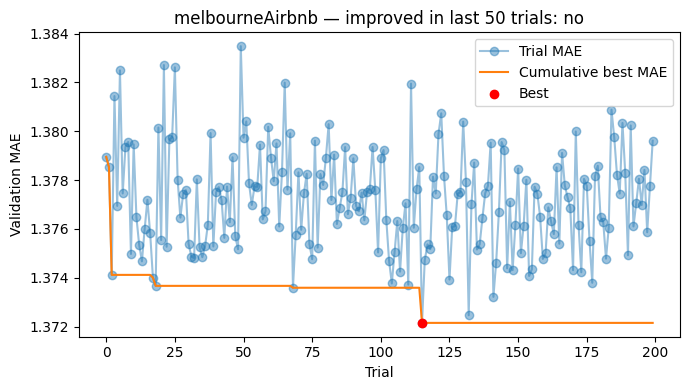

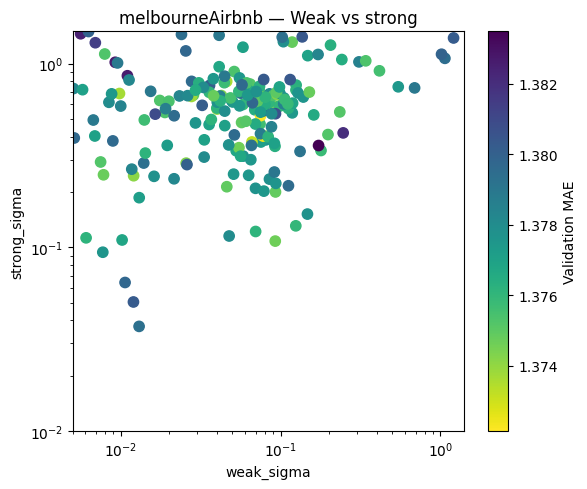

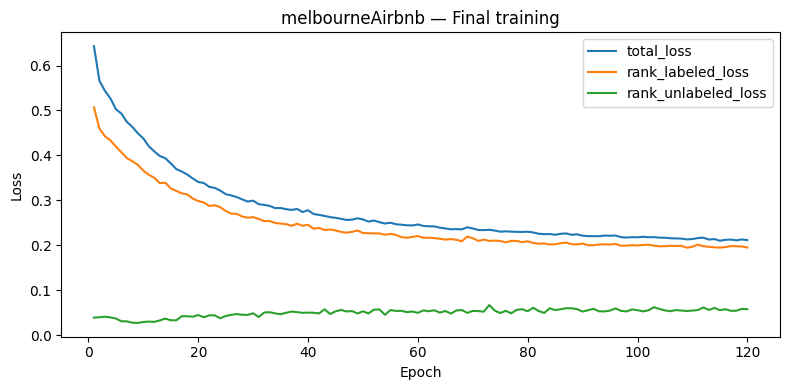

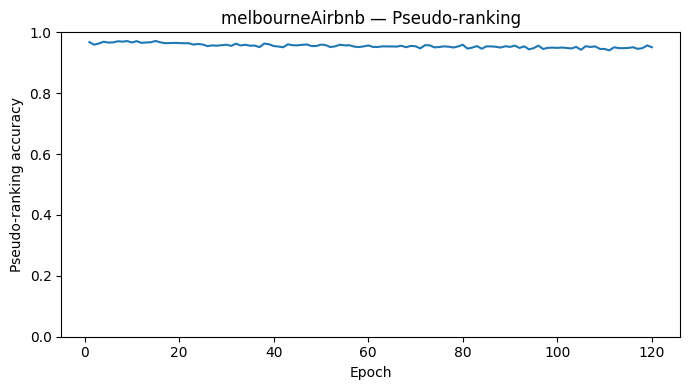

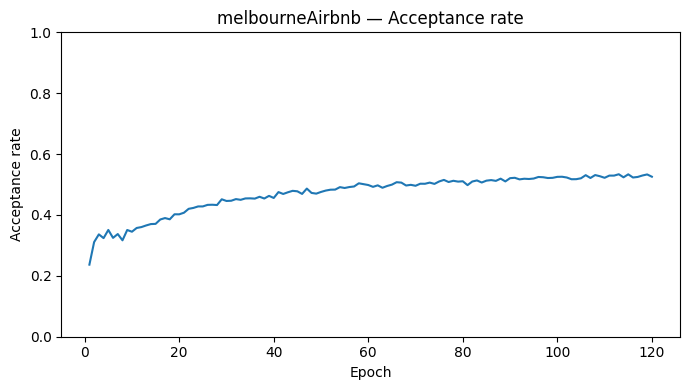

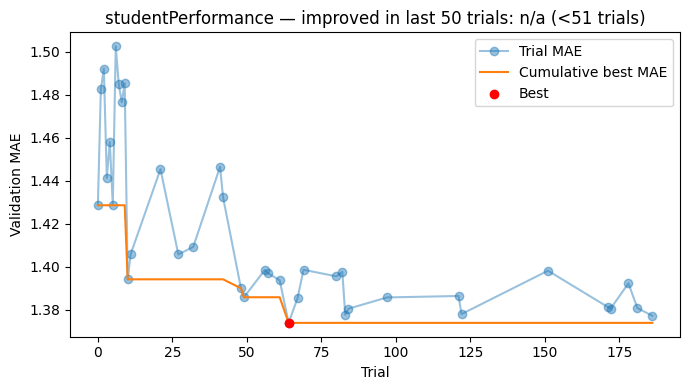

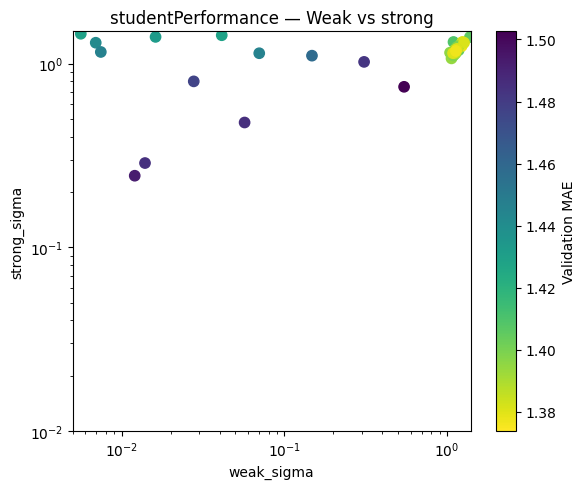

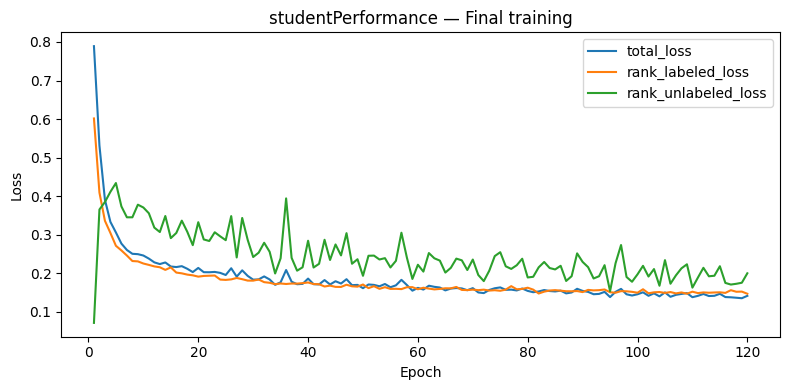

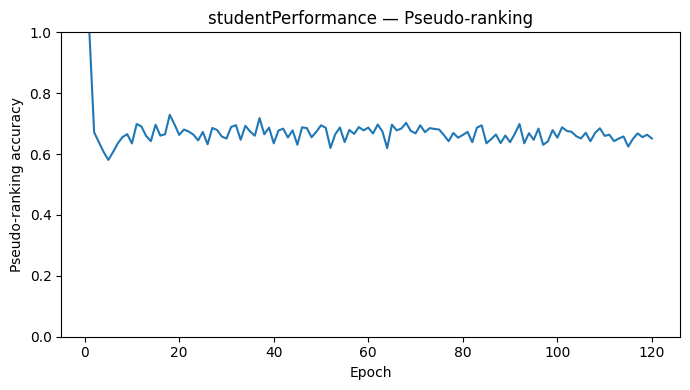

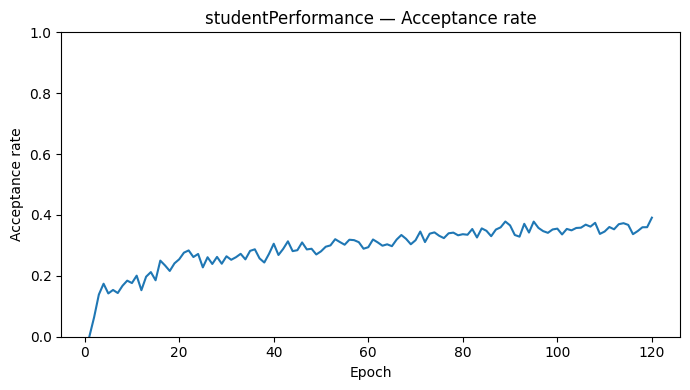

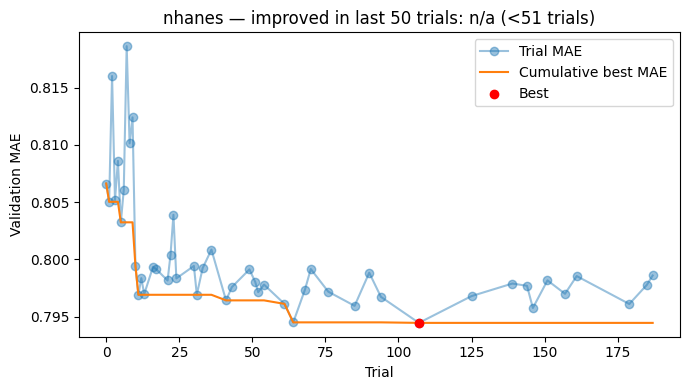

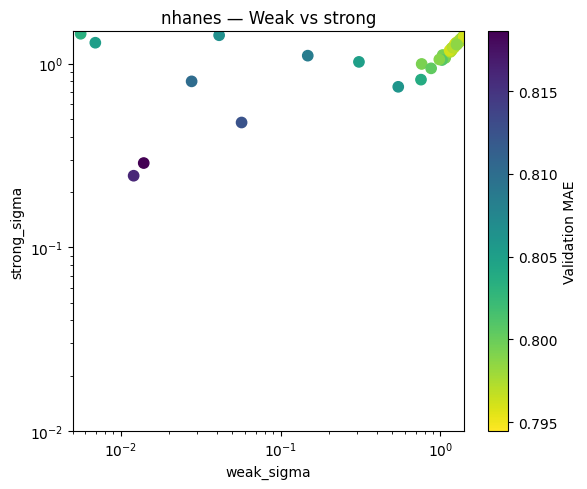

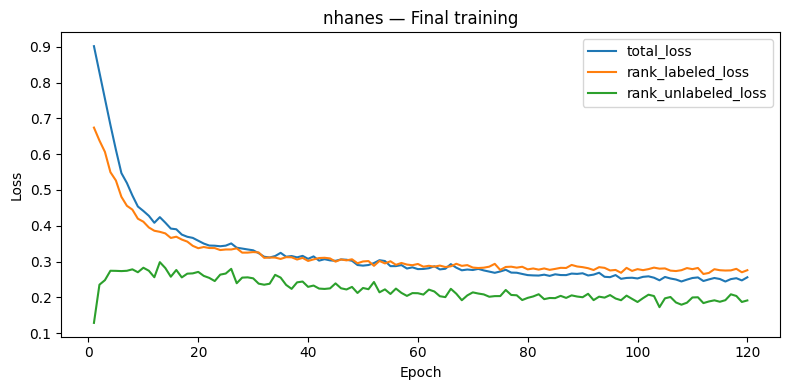

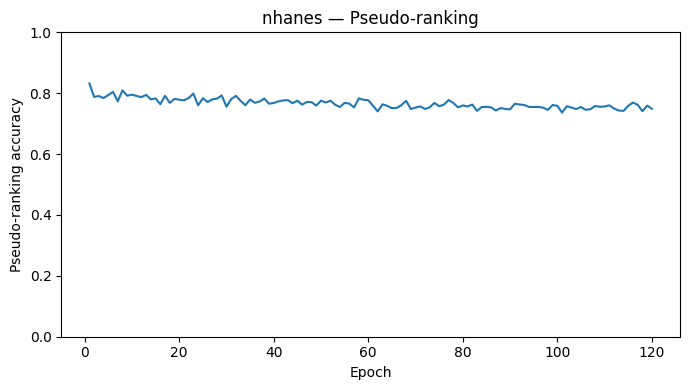

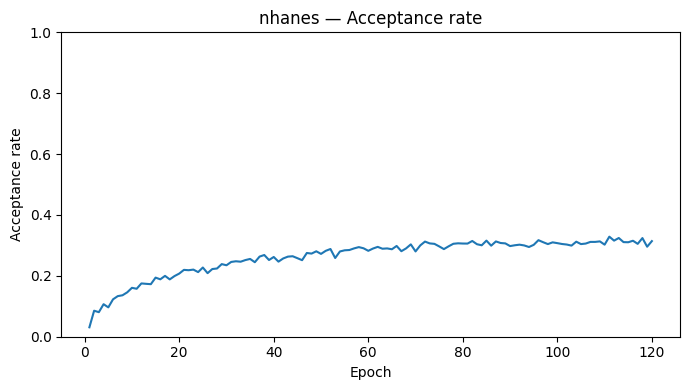

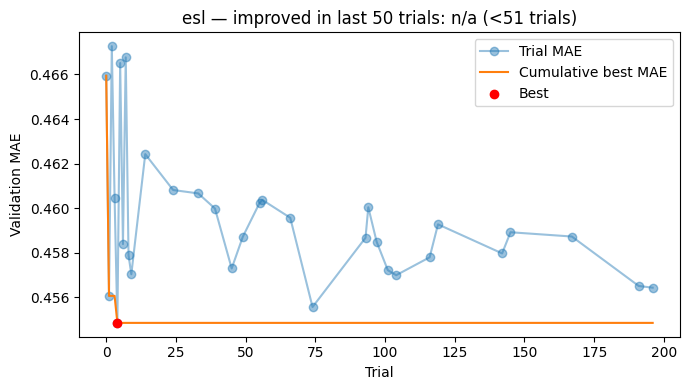

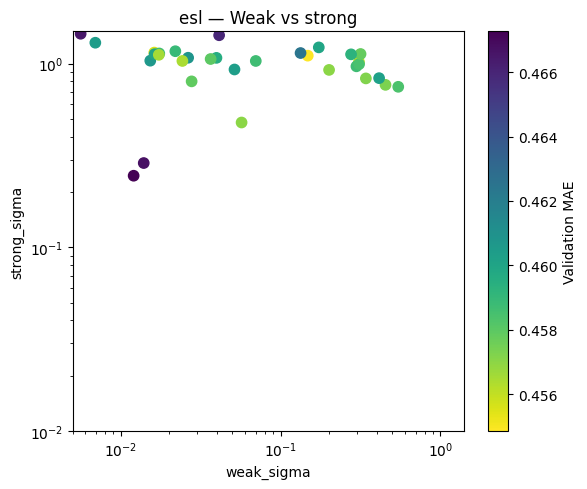

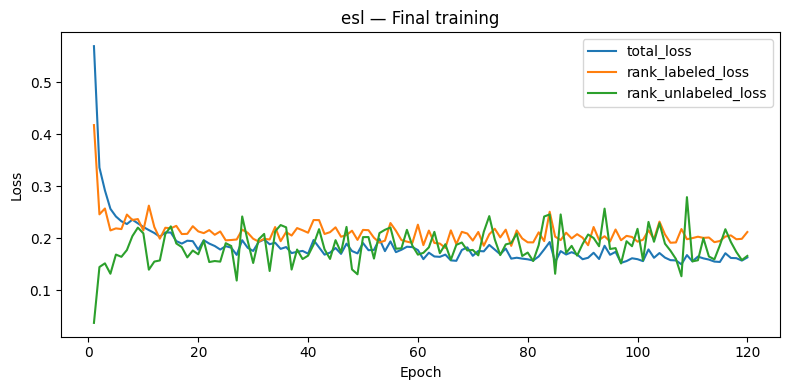

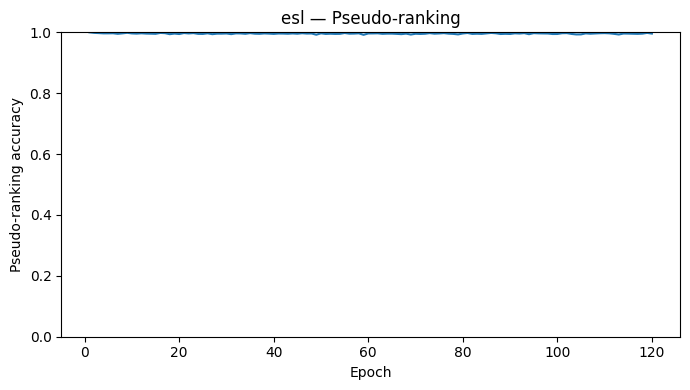

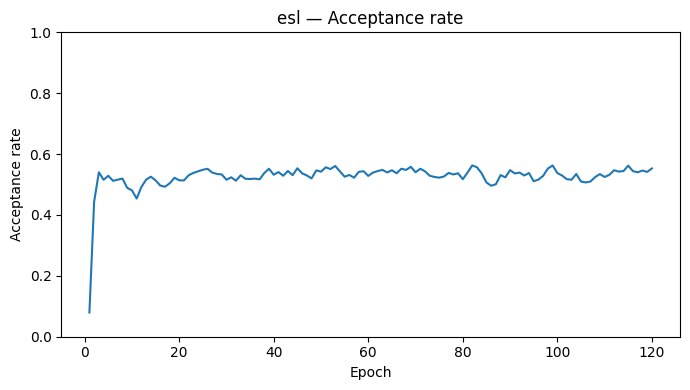

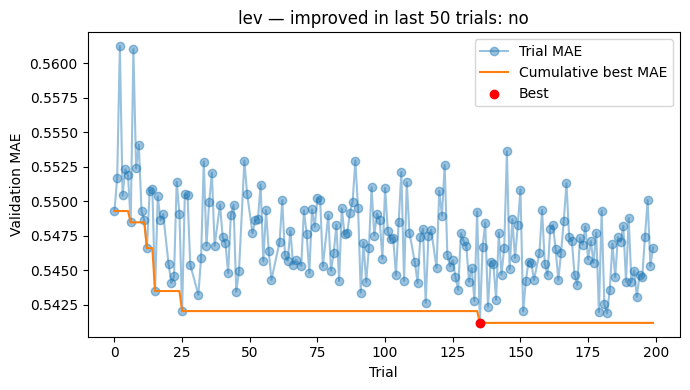

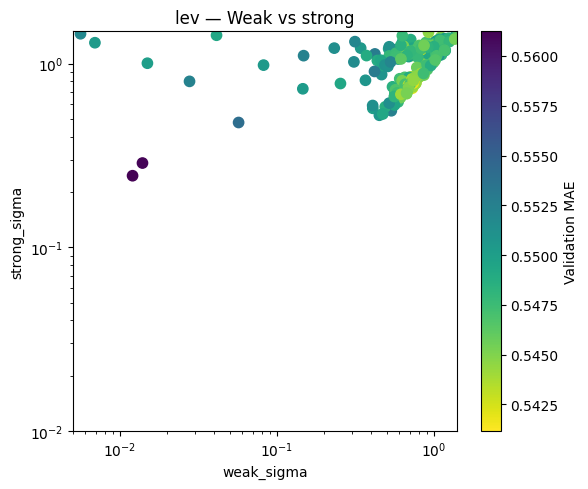

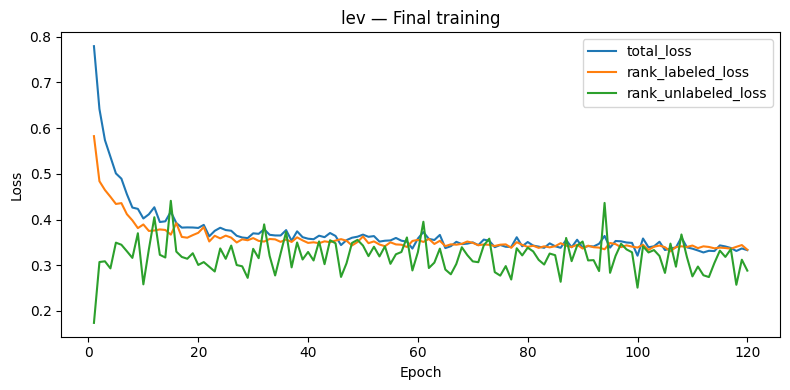

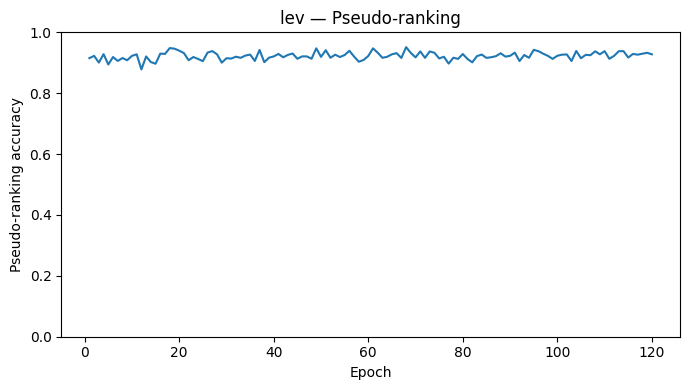

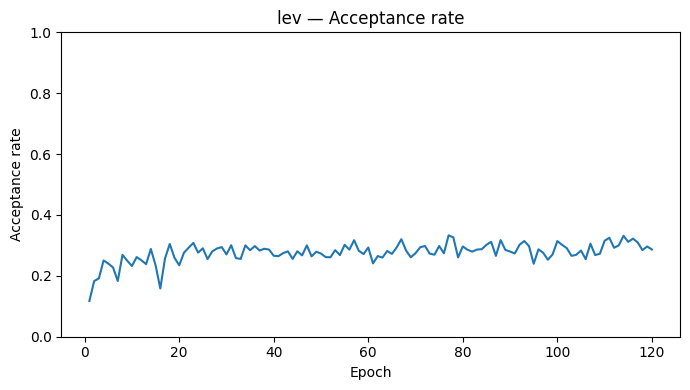

In [18]:
def save_plot(path, title):
    plt.title(title)
    plt.tight_layout()
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()


def make_plots(dataset_name):
    study = studies[dataset_name]
    data = optuna_data[dataset_name]
    trials = trials_frame(study, dataset_name, data)
    valid = trials[(trials["state"] == "COMPLETE") & trials["val_MAE"].notna()]
    final_history = final_histories[dataset_name]
    plots = dataset_dirs[dataset_name] / "plots"

    valid = valid.sort_values("trial").reset_index(drop=True)
    valid["cumulative_best_MAE"] = valid["val_MAE"].cummin()
    previous = valid.iloc[:-50] if len(valid) > 50 else None
    improved = None if previous is None else valid["val_MAE"].min() < previous["val_MAE"].min()
    convergence = "n/a (<51 trials)" if improved is None else ("yes" if improved else "no")

    plt.figure(figsize=(7, 4))
    plt.plot(valid["trial"], valid["val_MAE"], marker="o", alpha=0.45, label="Trial MAE")
    plt.plot(valid["trial"], valid["cumulative_best_MAE"], label="Cumulative best MAE")
    best = valid.loc[valid["val_MAE"].idxmin()]
    plt.scatter(best["trial"], best["val_MAE"], color="red", zorder=3, label="Best")
    plt.xlabel("Trial"); plt.ylabel("Validation MAE"); plt.legend()
    save_plot(plots / "01_optuna_history.png", f"{dataset_name} — improved in last 50 trials: {convergence}")

    plt.figure(figsize=(6, 5))
    scatter = plt.scatter(
        valid[WEAK_AXIS], valid[STRONG_AXIS], c=valid["val_MAE"],
        cmap="viridis_r", s=55,
    )
    plt.colorbar(scatter, label="Validation MAE")
    plt.xlabel(WEAK_AXIS); plt.ylabel(STRONG_AXIS)
    plt.xscale("log"); plt.yscale("log")
    plt.xlim(0.005, 1.40); plt.ylim(0.01, 1.50)
    save_plot(plots / "02_weak_vs_strong.png", f"{dataset_name} — Weak vs strong")

    plt.figure(figsize=(8, 4))
    for column in ["total_loss", "rank_labeled_loss", "rank_unlabeled_loss"]:
        plt.plot(final_history["epoch"], final_history[column], label=column)
    plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend()
    save_plot(plots / "03_final_training_loss.png", f"{dataset_name} — Final training")

    plt.figure(figsize=(7, 4))
    plt.plot(final_history["epoch"], final_history["pseudo_rank_accuracy_non_tie"])
    plt.xlabel("Epoch"); plt.ylabel("Pseudo-ranking accuracy"); plt.ylim(0, 1)
    save_plot(plots / "04_pseudo_rank_accuracy.png", f"{dataset_name} — Pseudo-ranking")

    plt.figure(figsize=(7, 4))
    plt.plot(final_history["epoch"], final_history["pseudo_accept_rate"])
    plt.xlabel("Epoch"); plt.ylabel("Acceptance rate"); plt.ylim(0, 1)
    save_plot(plots / "05_acceptance_rate.png", f"{dataset_name} — Acceptance rate")


for dataset_name in RUN_DATASETS:
    make_plots(dataset_name)

# 16. Final Summary

In [19]:
print("Best configuration")
display(all_best_results[[
    "dataset", "best_weak", "best_strong", "best_val_MAE",
    "test_MAE", "test_QWK", "final_pseudo_rank_accuracy",
]])

print("Ranking best validation MAE")
display(all_best_results[[
    "dataset", "best_val_MAE", "best_weak", "best_strong",
]].sort_values("best_val_MAE").reset_index(drop=True))

print("Final test metrics")
display(all_best_results[[
    "dataset", "test_R2", "test_Spearman", "test_MAE", "test_RMSE", "test_QWK",
]].sort_values("test_MAE").reset_index(drop=True))

Best configuration


,dataset,best_weak,best_strong,best_val_MAE,test_MAE,test_QWK,final_pseudo_rank_accuracy
0,melbourneAirbnb,0.074954,0.520683,1.372154,1.288659,0.802598,0.951062
1,studentPerformance,1.225239,1.245054,1.373779,1.307495,0.270594,0.651288
2,nhanes,1.398780,1.411422,0.794468,0.787253,0.155340,0.748842
3,esl,0.147909,1.105682,0.454860,0.416936,0.874819,0.995804
4,lev,0.765054,0.783882,0.541168,0.599011,0.511525,0.927739


Ranking best validation MAE


,dataset,best_val_MAE,best_weak,best_strong
0,esl,0.454860,0.147909,1.105682
1,lev,0.541168,0.765054,0.783882
2,nhanes,0.794468,1.398780,1.411422
3,melbourneAirbnb,1.372154,0.074954,0.520683
4,studentPerformance,1.373779,1.225239,1.245054


Final test metrics


,dataset,test_R2,test_Spearman,test_MAE,test_RMSE,test_QWK
0,esl,0.823771,0.926788,0.416936,0.562577,0.874819
1,lev,0.103476,0.511293,0.599011,0.900441,0.511525
2,nhanes,-0.016725,0.244660,0.787253,0.997298,0.155340
3,melbourneAirbnb,0.660467,0.809086,1.288659,1.750281,0.802598
4,studentPerformance,0.092833,0.395773,1.307495,1.688458,0.270594
